# Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

Entrada: `datos/noticias.csv` (400 noticias, opción C: 200 de La República + 200 de El Comercio).

**Qué se compara** (los tres modelos se evalúan contra la **misma etiqueta de referencia**, `etiqueta`, que sale del mapeo explícito de la sección del diario hecho en la Parte 1):

1. **Zero-shot**: un modelo NLI sin entrenamiento → piso mínimo a superar.
2. **LLM (Gemini)**: etiqueta los 400 titulares con un prompt estructurado (supervisión débil) + auditoría humana de 20 casos.
3. **Transformer fine-tuned**: `distilbert-base-multilingual-cased` entrenado con el split 70/15/15.

El conjunto de **test** se separa al inicio y no se usa para nada hasta la evaluación final.

> **Antes de ejecutar:** crea un archivo `.env` en esta carpeta con una sola línea: `GEMINI_API_KEY=tu_clave` (la clave se obtiene gratis en https://aistudio.google.com/apikey). El `.gitignore` impide que se suba a GitHub.

In [ ]:
%pip install -q "transformers>=4.46" "accelerate>=1.0" torch scikit-learn seaborn matplotlib google-genai python-dotenv

Note: you may need to restart the kernel to use updated packages.


## 0. Configuración

In [ ]:
import json, os, random, re, time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
DATOS, MODELO = Path("datos"), Path("modelo")
MODELO.mkdir(exist_ok=True)

df = pd.read_csv(DATOS / "noticias.csv")
print("Noticias:", df.shape)
df.groupby(["medio", "etiqueta"]).size().unstack()

Noticias: (383, 7)


etiqueta,ciencia_tecnologia,deportes,economia,politica
medio,,,,
El Comercio,95,98,99,91


## 1. Partición estratificada 70 / 15 / 15 (`random_state=42`)

Se estratifica por **categoría y medio** a la vez, para que train, validación y test tengan la misma mezcla de La República y El Comercio. El test queda aislado desde aquí.

In [ ]:
estrato = df["etiqueta"] + "|" + df["medio"]
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=estrato, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50,
                                   stratify=temp_df["etiqueta"] + "|" + temp_df["medio"],
                                   random_state=SEED)
for nombre, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nombre:5s}: {len(d):3d} filas ({len(d)/len(df):.0%})  ",
          d["etiqueta"].value_counts().reindex(CATEGORIAS).tolist())

train: 268 filas (70%)   [64, 69, 69, 66]
val  :  57 filas (15%)   [14, 15, 14, 14]
test :  58 filas (15%)   [13, 15, 15, 15]


## 2. Línea base Zero-Shot (sin fine-tuning)

Modelo: `Recognai/bert-base-spanish-wwm-cased-xnli` (BERT en español entrenado en inferencia lingüística; ~440 MB, más liviano que `xlm-roberta-large-xnli` de ~2,2 GB).
Se evalúan **40 titulares del conjunto de test** (muestra estratificada por categoría), así la comparación con el modelo final es justa.

In [ ]:
from transformers import pipeline

zs = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli")

# Etiquetas en lenguaje natural para que el modelo NLI las entienda
NOMBRES = {"política": "politica", "economía": "economia",
           "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}

zs_df = train_test_split(test_df, train_size=40, stratify=test_df["etiqueta"], random_state=SEED)[0].copy()
t0 = time.time()
salidas = zs(zs_df["titular"].tolist(), candidate_labels=list(NOMBRES),
             hypothesis_template="Esta noticia trata sobre {}.")
lat_zs = (time.time() - t0) / len(zs_df)
zs_df["pred_zs"] = [NOMBRES[s["labels"][0]] for s in salidas]

acc_zs = accuracy_score(zs_df["etiqueta"], zs_df["pred_zs"])
f1_zs = f1_score(zs_df["etiqueta"], zs_df["pred_zs"], average="macro")
print(f"Zero-shot (n={len(zs_df)}) → Accuracy: {acc_zs:.3f} | F1 macro: {f1_zs:.3f} | {lat_zs*1000:.0f} ms/titular")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Zero-shot (n=40) → Accuracy: 0.675 | F1 macro: 0.658 | 77 ms/titular


## 3. Supervisión débil con un LLM (Gemini)

Se envían los titulares en lotes de 25 con un prompt estructurado que obliga a responder en JSON con una de las 4 categorías y una confianza entre 0 y 1. Las respuestas se guardan en `datos/etiquetas_llm.csv`; si el archivo ya existe, **no se vuelve a llamar a la API** (ahorra cuota y hace el notebook reproducible).

In [ ]:
from dotenv import load_dotenv
from google import genai
from google.genai import types

load_dotenv(".env")   # el .env debe estar en la misma carpeta que este notebook
assert os.getenv("GEMINI_API_KEY"), "Falta GEMINI_API_KEY en el archivo .env"
cliente = genai.Client(http_options=types.HttpOptions(timeout=90_000))   # 90 s máx. por petición

# Se usan en este orden; si uno falla (saturado o retirado) se pasa al siguiente.
# Los "lite" son los más rápidos. Los nombres cambian con el tiempo: ajusta la lista si hace falta.
MODELOS_GEMINI = ["gemini-3.1-flash-lite", "gemini-2.5-flash-lite", "gemini-3-flash-preview", "gemini-2.5-flash"]

PROMPT = '''Eres un editor de un diario peruano. Clasifica cada titular en EXACTAMENTE una categoría:
- politica: gobierno, Congreso, elecciones, partidos, justicia y funcionarios públicos.
- economia: mercados, empresas, empleo, precios, impuestos, finanzas personales, comercio.
- deportes: fútbol, vóley y cualquier competencia o deportista.
- ciencia_tecnologia: ciencia, salud, medio ambiente, tecnología, internet, IA, videojuegos.

Responde SOLO con una lista JSON, un objeto por titular y en el mismo orden:
[{"id": <id>, "categoria": "<categoria>", "confianza": <número entre 0 y 1>}]

Titulares:
'''

def etiquetar_lote(lote, modelo):
    texto = PROMPT + "\n".join(f'{i}. {t}' for i, t in lote)
    r = cliente.models.generate_content(
        model=modelo, contents=texto,
        config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json"))
    return json.loads(r.text)

In [ ]:
RUTA_LLM = DATOS / "etiquetas_llm.csv"
RUTA_PARCIAL = DATOS / "raw" / "llm_parcial.json"   # avance guardado lote a lote
RUTA_PARCIAL.parent.mkdir(parents=True, exist_ok=True)

if RUTA_LLM.exists():
    llm = pd.read_csv(RUTA_LLM)
    print("Usando etiquetas guardadas:", RUTA_LLM)
else:
    resultados = {int(k): v for k, v in json.loads(RUTA_PARCIAL.read_text()).items()} if RUTA_PARCIAL.exists() else {}
    titulares = list(enumerate(df["titular"]))
    lotes = [titulares[k:k + 25] for k in range(0, len(titulares), 25)]
    descartados, t0, n_llamadas = set(), time.time(), 0
    for n, lote in enumerate(lotes, 1):
        if all(i in resultados for i, _ in lote):
            continue                                   # ya etiquetado en una ejecución anterior
        for modelo in [m for m in MODELOS_GEMINI if m not in descartados]:
            try:
                for r in etiquetar_lote(lote, modelo):
                    resultados[int(r["id"])] = {**r, "modelo": modelo}
                n_llamadas += 1
                print(f"Lote {n}/{len(lotes)} ✓ con {modelo}  ({time.time() - t0:.0f} s)", flush=True)
                break
            except Exception as e:
                msg = str(e)
                print(f"Lote {n}/{len(lotes)}: {modelo} falló → {msg[:70]}", flush=True)
                if "404" in msg or "NOT_FOUND" in msg:
                    descartados.add(modelo)            # modelo retirado: no volver a intentarlo
                time.sleep(5)
        RUTA_PARCIAL.write_text(json.dumps(resultados, ensure_ascii=False))
        time.sleep(4)                                  # respeta el límite por minuto del plan gratuito
    lat_llm = (time.time() - t0) / max(n_llamadas * 25, 1)

    faltan = [i for i, _ in titulares if i not in resultados]
    llm = pd.DataFrame({
        "titular": df["titular"],
        "etiqueta_llm": [resultados.get(i, {}).get("categoria") for i in range(len(df))],
        "confianza": [resultados.get(i, {}).get("confianza") for i in range(len(df))],
        "modelo_llm": [resultados.get(i, {}).get("modelo") for i in range(len(df))],
        "fecha": date.today().isoformat(),
    })
    llm["latencia_s"] = round(lat_llm, 3)
    if faltan:
        print(f"⚠️ Faltan {len(faltan)} titulares sin etiqueta: vuelve a ejecutar ESTA celda "
              "(retoma desde donde quedó).")
    else:
        llm.to_csv(RUTA_LLM, index=False)
        print("Guardado:", RUTA_LLM)

print("Sin respuesta o fuera de las 4 categorías:", (~llm["etiqueta_llm"].isin(CATEGORIAS)).sum())
llm.head()

Lote 14/16 ✓ con gemini-3.1-flash-lite  (7 s)
Guardado: datos/etiquetas_llm.csv
Sin respuesta o fuera de las 4 categorías: 0


,titular,etiqueta_llm,confianza,modelo_llm,fecha,latencia_s
0,Canales de televisión para mirar FC Barcelona ...,deportes,1.0,gemini-3-flash-preview,2026-10-19,0.446
1,¿Cambia el fútbol por la NFL? Mbappé muestra s...,deportes,1.0,gemini-3-flash-preview,2026-10-19,0.446
2,“Una oportunidad para reconocer todo lo que el...,deportes,1.0,gemini-3-flash-preview,2026-10-19,0.446
3,Como en sus mejores tiempos: el lujo de Neymar...,deportes,1.0,gemini-3-flash-preview,2026-10-19,0.446
4,“Es el mejor de todos los tiempos”: La curiosa...,deportes,1.0,gemini-3-flash-preview,2026-10-19,0.446


### 3.1 Auditoría humana de 20 predicciones al azar

Lee cada titular y decide si la categoría que puso Gemini es correcta. Luego escribe en `DESACUERDOS` los **números** de los casos en que **no** estás de acuerdo (por ejemplo `[3, 15]`). Si estás de acuerdo con todos, déjalo vacío: `[]`.

In [ ]:
auditoria = llm.sample(20, random_state=SEED).reset_index(drop=True)
auditoria.index = auditoria.index + 1
auditoria[["titular", "etiqueta_llm", "confianza"]]

,titular,etiqueta_llm,confianza
1,Reinfo: Decano del Colegio de Abogados de Lore...,politica,0.95
2,El Niño retrasaría la recuperación económica d...,economia,0.95
3,Precio del dólar del lunes 12 de octubre: a cu...,economia,0.99
4,Científicos descubren cómo predecir cuándo una...,ciencia_tecnologia,0.99
5,Gol de Andy Polo: Universitario vence 2-0 a Al...,deportes,1.00
6,Noruega estudia prohibir temporalmente las gaf...,ciencia_tecnologia,0.95
7,VIDEO: Universitario goleó 4-1 a Alianza Atlét...,deportes,1.00
8,A falta de una etapa: Eduardo Castro mantiene ...,deportes,1.00
9,Las empresas de IA son incapaces de controlar ...,ciencia_tecnologia,1.00
10,"Luis Felipe Gazitúa, del Consejo Empresarial C...",economia,1.00


In [ ]:
DESACUERDOS = []   # <- escribe aquí los números con los que NO estás de acuerdo, ej. [3, 15]

acuerdo = 20 - len(DESACUERDOS)
pct_acuerdo = acuerdo / 20
auditoria["acuerdo_humano"] = ~auditoria.index.isin(DESACUERDOS)
auditoria.to_csv(DATOS / "auditoria_llm.csv", index_label="n")
print(f"Acuerdo LLM-Humano: {acuerdo}/20 = {pct_acuerdo:.0%}")

Acuerdo LLM-Humano: 20/20 = 100%


**Comentario de la auditoría:** *Gemini acertó en los 20 casos revisados (20/20 = 100 %). Aun así, comparado con la etiqueta de sección en el test, su F1 macro es 0,895 y no 1,0: los desacuerdos suelen darse en titulares fronterizos, por ejemplo notas de economía con actores políticos (Congreso, ministros) o notas de la sección Tecnología que tratan de salud o de empresas, donde la sección del diario y el contenido del titular no coinciden del todo.*

In [ ]:
# Calidad del LLM en el MISMO test que usarán los otros modelos
llm_test = test_df[["titular", "etiqueta"]].merge(llm[["titular", "etiqueta_llm"]], on="titular", how="left")
acc_llm = accuracy_score(llm_test["etiqueta"], llm_test["etiqueta_llm"].fillna("sin_respuesta"))
f1_llm = f1_score(llm_test["etiqueta"], llm_test["etiqueta_llm"].fillna("sin_respuesta"),
                  average="macro", labels=CATEGORIAS)
lat_llm = float(llm["latencia_s"].iloc[0]) if "latencia_s" in llm else float("nan")
print(f"LLM en test (n={len(llm_test)}) → Accuracy: {acc_llm:.3f} | F1 macro: {f1_llm:.3f}")

LLM en test (n=58) → Accuracy: 0.897 | F1 macro: 0.895


## 4. Fine-tuning de `distilbert-base-multilingual-cased`

- Entrada: solo el **titular** (igual que en el dashboard, donde el usuario escribe un titular).
- Etiqueta de entrenamiento: `etiqueta` (mapeo de sección). Si quieres probar supervisión débil pura, cambia `COL_ENTRENAMIENTO = "etiqueta_llm"`.
- 3 épocas, batch 16, evaluación en validación al final de cada época, se guarda el mejor modelo según **F1 macro**.

En una Mac con chip M1/M2/M3 tarda ~3–6 min; en CPU Intel, ~10–20 min.

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          Trainer, TrainingArguments, DataCollatorWithPadding)

BASE = "distilbert-base-multilingual-cased"
COL_ENTRENAMIENTO = "etiqueta"
label2id = {c: i for i, c in enumerate(CATEGORIAS)}
id2label = {i: c for c, i in label2id.items()}

if COL_ENTRENAMIENTO == "etiqueta_llm":
    train_df = train_df.merge(llm[["titular", "etiqueta_llm"]], on="titular", how="left").dropna()

tok = AutoTokenizer.from_pretrained(BASE)

class Titulares(torch.utils.data.Dataset):
    def __init__(self, d, col):
        self.enc = tok(d["titular"].tolist(), truncation=True, max_length=64)
        self.y = [label2id[c] for c in d[col]]
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.y[i]
        return item

ds_train = Titulares(train_df, COL_ENTRENAMIENTO)
ds_val, ds_test = Titulares(val_df, "etiqueta"), Titulares(test_df, "etiqueta")

def metricas(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred),
            "f1_macro": f1_score(p.label_ids, pred, average="macro")}

modelo = AutoModelForSequenceClassification.from_pretrained(
    BASE, num_labels=4, id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir=str(MODELO), num_train_epochs=3,
    per_device_train_batch_size=16, per_device_eval_batch_size=32,
    learning_rate=5e-5, weight_decay=0.01, warmup_steps=5,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="f1_macro",
    logging_strategy="epoch", report_to="none", seed=SEED)

trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=metricas)
trainer.train()
pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])[
    ["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/opt/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.269815,1.002066,0.824561,0.821996
2,0.792385,0.538375,0.929825,0.929620
3,0.435395,0.389448,0.929825,0.930190


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,1.002066,0.824561,0.821996
1,2.0,0.538375,0.929825,0.929620
2,3.0,0.389448,0.929825,0.930190


In [ ]:
trainer.save_model(str(MODELO))
tok.save_pretrained(str(MODELO))
print("Modelo guardado en", MODELO.resolve())

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en /Users/valeria/Desktop/ESTUDIOS/CIENCIAS DE DATOS/Python/Repositorios/Python-intermedio/Python-intermedio/Tarea_1/modelo


## 5. Evaluación final en el conjunto de TEST reservado

In [ ]:
t0 = time.time()
pred = trainer.predict(ds_test)
lat_ft = (time.time() - t0) / len(ds_test)
y_true = pred.label_ids
y_pred = pred.predictions.argmax(-1)

acc_ft = accuracy_score(y_true, y_pred)
f1_ft = f1_score(y_true, y_pred, average="macro")
print(f"TEST (n={len(y_true)}) → Accuracy: {acc_ft:.3f} | F1 macro: {f1_ft:.3f}\n")
print(classification_report(y_true, y_pred, target_names=CATEGORIAS, digits=3))

/opt/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TEST (n=58) → Accuracy: 0.862 | F1 macro: 0.863

                    precision    recall  f1-score   support

          politica      0.857     0.923     0.889        13
          economia      0.684     0.867     0.765        15
          deportes      1.000     1.000     1.000        15
ciencia_tecnologia      1.000     0.667     0.800        15

          accuracy                          0.862        58
         macro avg      0.885     0.864     0.863        58
      weighted avg      0.886     0.862     0.863        58



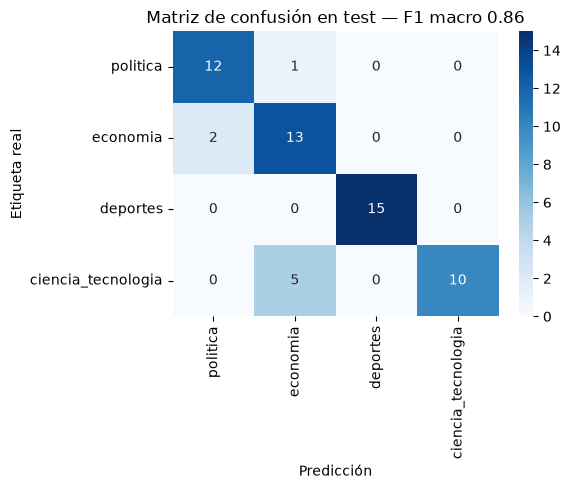

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
plt.xlabel("Predicción"); plt.ylabel("Etiqueta real")
plt.title(f"Matriz de confusión en test — F1 macro {f1_ft:.2f}")
plt.tight_layout(); plt.show()

In [ ]:
f1_cat = pd.Series(f1_score(y_true, y_pred, average=None), index=CATEGORIAS).sort_values()
print(f"Mejor categoría: {f1_cat.index[-1]} (F1 {f1_cat.iloc[-1]:.2f}) | "
      f"Peor: {f1_cat.index[0]} (F1 {f1_cat.iloc[0]:.2f})")

# Errores para entender la causa
test_eval = test_df.assign(pred=[id2label[i] for i in y_pred])
errores = test_eval[test_eval["etiqueta"] != test_eval["pred"]][["medio", "etiqueta", "pred", "titular"]]
errores

Mejor categoría: deportes (F1 1.00) | Peor: economia (F1 0.76)


,medio,etiqueta,pred,titular
207,El Comercio,economia,politica,Invocación por el Perú
329,El Comercio,ciencia_tecnologia,economia,Perú: más de 200 operativos en el año en Madre...
351,El Comercio,ciencia_tecnologia,economia,Trump llama a Musk un “tesoro nacional” tras c...
235,El Comercio,ciencia_tecnologia,economia,"Netflix despedirá a unos 1.000 empleados, el 6..."
204,El Comercio,economia,politica,Pensionistas de la ONP recibirán su pensión en...
347,El Comercio,ciencia_tecnologia,economia,Informe Planeta Vivo 2026: la fauna silvestre ...
314,El Comercio,politica,economia,Ministro Guillermo Shinno presenta propuesta d...
370,El Comercio,ciencia_tecnologia,economia,Finlandia frena la construcción de dos centros...


**Reflexión por categoría (test, n = 58):**

- **Mejor desempeño: `deportes` (F1 1,00).** Acertó los 15 casos. Su vocabulario es muy distintivo (clubes, jugadores, "partido", "EN VIVO", marcadores) y casi no se cruza con las otras secciones.
- **Peor desempeño: `economia` (F1 0,76).** No porque falle mucho al reconocer sus propias notas (13 de 15), sino porque **absorbe errores de otras categorías**: 5 noticias de `ciencia_tecnologia` fueron predichas como economía. Son notas de la sección Tecnología con contenido empresarial o ambiental ("Netflix despedirá a unos 1.000 empleados", "Trump llama a Musk un tesoro nacional", "Finlandia frena la construcción de dos centros [de datos]", "Informe Planeta Vivo 2026"). El titular habla de empresas, empleo o recursos, aunque el diario lo publicó en Tecnología.
- **`politica` ↔ `economia`** se confunden en 3 casos ("Pensionistas de la ONP…", "Ministro Guillermo Shinno presenta propuesta…"): comparten actores del Estado (ministros, ONP, Congreso), y la diferencia está en el tema de fondo, no en las palabras.
- **`ciencia_tecnologia`** es la categoría menos homogénea (IA, videojuegos, salud, clima, ecología), por eso tuvo el menor *recall* (10 de 15). Parte del error viene de la propia etiqueta: la sección "Tecnología" de El Comercio agrupa temas que un lector clasificaría como economía o medio ambiente.

## 6. Comparativa y decisión

In [ ]:
comparativa = pd.DataFrame([
    {"modelo": "Zero-shot (BERT-es XNLI)", "n_eval": len(zs_df), "accuracy": acc_zs, "f1_macro": f1_zs,
     "ms_por_titular": lat_zs * 1000, "costo": "Gratis, local, sin entrenar"},
    {"modelo": f"LLM débil ({llm['modelo_llm'].mode()[0]})", "n_eval": len(llm_test), "accuracy": acc_llm,
     "f1_macro": f1_llm, "ms_por_titular": lat_llm * 1000, "costo": "API externa: cuota/pago y red"},
    {"modelo": "DistilBERT fine-tuned", "n_eval": len(y_true), "accuracy": acc_ft, "f1_macro": f1_ft,
     "ms_por_titular": lat_ft * 1000, "costo": "Entrenar una vez (minutos), luego local"},
]).round(3)
comparativa

,modelo,n_eval,accuracy,f1_macro,ms_por_titular,costo
0,Zero-shot (BERT-es XNLI),40,0.675,0.658,76.586,"Gratis, local, sin entrenar"
1,LLM débil (gemini-3.1-flash-lite),58,0.897,0.895,446.000,API externa: cuota/pago y red
2,DistilBERT fine-tuned,58,0.862,0.863,11.919,"Entrenar una vez (minutos), luego local"


In [ ]:
# Métricas que usará el dashboard (archivo liviano, sí se sube a GitHub)
json.dump({"f1_macro_test": round(f1_ft, 4), "accuracy_test": round(acc_ft, 4),
           "f1_zero_shot": round(f1_zs, 4), "f1_llm_test": round(f1_llm, 4),
           "acuerdo_llm_humano": acuerdo, "pct_acuerdo_llm_humano": round(pct_acuerdo, 4),
           "modelo_base": BASE, "modelo_llm": llm["modelo_llm"].mode()[0]},
          open(MODELO / "metricas.json", "w"), indent=2)
comparativa.to_csv(MODELO / "comparativa.csv", index=False)

print("=== Para copiar en el comentario de entrega ===")
print(f"Resultados Test: F1 Macro: {f1_ft:.2f} | Zero-shot: {f1_zs:.2f} | Acuerdo LLM-Humano: {acuerdo}/20")

=== Para copiar en el comentario de entrega ===
Resultados Test: F1 Macro: 0.86 | Zero-shot: 0.66 | Acuerdo LLM-Humano: 20/20


**Decisión para un entorno real**

| Modelo | F1 macro | Costo y latencia |
|---|---|---|
| Zero-shot (BERT-es XNLI) | 0,66 | Gratis y local, sin entrenar |
| LLM débil (Gemini) | 0,90 | API externa: ~0,45 s por titular, cuota limitada |
| DistilBERT fine-tuned | 0,86 | Unos minutos de entrenamiento, luego local en milisegundos |

**Elegiría DistilBERT fine-tuned para producción.** Gemini obtuvo el F1 más alto (0,90 frente a 0,86), pero en este mismo trabajo mostró sus riesgos operativos: errores 503 (modelo saturado) y 429 (cuota agotada) obligaron a reintentar varios lotes, cada consulta tarda cientos de milisegundos y depende de red y de un costo por uso. DistilBERT corre en local, responde en milisegundos, no tiene costo por consulta y da siempre la misma respuesta para el mismo titular. La diferencia de 4 puntos se puede reducir usando al LLM como lo que mejor hace: **etiquetar más noticias** para reentrenar el modelo pequeño. El zero-shot sirve como prototipo inmediato, pero queda 20 puntos por debajo.